# 03 · Evaluation: which method detects known adverse reactions best, and earliest?

Two reference sets, two questions:

1. **Which method ranks known reactions highest?** Reference: the current FDA
   label of the 300 most reported drugs (openFDA). A pair is *positive* if the
   reaction is in a safety section of the label, *negative* if it is not
   mentioned anywhere (`make reference`).
2. **Which method flags them earliest?** Reference: reactions added to the
   label by a safety-related labelling change (SrLC) between 2016 and 2026.
   The database is replayed quarter by quarter to find when each method first
   flags each pair (`python -m faers.benchmark`).

A third contender combines the four scores with features of the reports
(seriousness, reporter type, dynamics) in a machine-learning model.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from faers import plotting as P
from faers.evaluate import (
    BASELINES,
    RANKING_SCORES,
    bootstrap_by_drug,
    compare_rankings,
    threshold_metrics,
)
from faers.ml import design_matrix, logistic_coefficients, out_of_fold_scores, pair_features
from faers.reference import load_label_reference
from faers.temporal import METHODS

DB = Path("../data/faers_warehouse.duckdb")
FIGURES = Path("../reports/figures")
TABLES = Path("../reports/tables")
TABLES.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(str(DB), read_only=True)

LABELS = {"prr": "PRR", "ror": "ROR", "bcpnn": "BCPNN", "ebgm": "EBGM"}

P.apply_style()


def save(fig, name):
    P.save(fig, name, folder=FIGURES)


COLORS = {**P.METHOD_COLORS, "Count (a)": P.NEUTRAL, "Observed/expected": P.NEUTRAL}


def dot_interval(ax, values, names, fmt="{:.2f}"):
    """Dot (mean) and line (95 % interval) per method, with the value written beside it."""
    y = np.arange(len(names))[::-1]
    for yi, name in zip(y, names):
        low, mean, high = values.loc[name, ["low", "mean", "high"]]
        ax.plot([low, high], [yi, yi], color=COLORS[name], linewidth=2.5, solid_capstyle="round")
        ax.plot(mean, yi, "o", color=COLORS[name], markersize=9, markeredgecolor=P.SURFACE,
                markeredgewidth=2, zorder=3)
        ax.annotate(fmt.format(mean), (high, yi), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=P.INK)
    ax.set_yticks(y, names)
    P.horizontal_bars(ax)
    ax.spines["left"].set_visible(False)

## 1. The label-based reference set

In [2]:
reference = load_label_reference(con)
print(f"Drugs with a usable label: {reference.drug.nunique()}")
print(reference.status.value_counts().to_string())

con.register("ref_pairs", reference[reference.status != "excluded"][["drug", "pt", "status"]])
pairs = con.execute("""
    SELECT s.*, r.status, s.a + s.b AS n_drug, s.a + s.c AS n_event, s.a / s.expected AS ratio
    FROM signal_scores AS s JOIN ref_pairs AS r USING (drug, pt)
""").df()
pairs["label"] = (pairs.status == "positive").astype(int)
print(f"\nEvaluation pairs: {len(pairs):,}, of which {pairs.label.mean():.1%} on the label")

Drugs with a usable label: 285
status
negative    951024
positive     30967
excluded      5448



Evaluation pairs: 981,991, of which 3.2% on the label


## 2. Ranking known reactions

Each method ranks pairs by the lower bound of its estimate (PRR and ROR lower
95 % limit, IC025, EB05), as used in practice. Two naive baselines show what
any method must beat: the raw number of reports and the observed/expected ratio.

In [3]:
serious = set(pd.read_csv("../ref/drug_induced_events.csv").pt)
pairs["serious_event"] = pairs.pt.isin(serious)
scores = {**RANKING_SCORES, **BASELINES}
table = pd.concat({
    "All clinical events": compare_rankings(pairs, scores),
    "Pairs with a ≥ 3": compare_rankings(pairs[pairs.a >= 3], scores),
    "Serious drug-induced events": compare_rankings(pairs[pairs.serious_event], scores),
}, axis=1)
table.to_csv(TABLES / "ranking_metrics.csv")
print(f"Serious drug-induced subset: {pairs.serious_event.sum():,} pairs, "
      f"{pairs[pairs.serious_event].label.mean():.1%} on the label")
table.round(3)

Serious drug-induced subset: 16,572 pairs, 15.4% on the label


All clinical events                     Pairs with a ≥ 3  \
                                  auc     ap p@100 p@1000              auc   
method                                                                       
PRR                             0.635  0.045  0.07  0.069            0.567   
ROR                             0.633  0.045  0.07  0.070            0.567   
BCPNN                           0.727  0.076  0.14  0.166            0.605   
EBGM                            0.714  0.065  0.08  0.092            0.590   
Count (a)                       0.859  0.247  0.57  0.551            0.810   
Observed/expected               0.492  0.029  0.01  0.015            0.496   

                                      Serious drug-induced events         \
                      ap p@100 p@1000                         auc     ap   
method                                                                     
PRR                0.065  0.07  0.071                       0.741  0.335   
ROR                0.066  0.07  0.072                       0.741  0.335   
BCPNN              0.083  0.14  0.166                       0.744  0.339   
EBGM               0.072  0.08  0.092                       0.743  0.337   
Count (a)          0.264  0.57  0.551                       0.754  0.360   
Observed/expected  0.054  0.04  0.028                       0.723  0.318   

                                
                  p@100 p@1000  
method                          
PRR                0.68  0.434  
ROR                0.68  0.435  
BCPNN              0.68  0.441  
EBGM               0.68  0.438  
Count (a)          0.59  0.494  
Observed/expected  0.68  0.416

The raw number of reports is a strong baseline on *all* clinical events:
labels list many common, non-specific reactions (nausea, headache, fatigue)
that are frequently reported with every drug. Disproportionality is designed
for the opposite: reactions reported *more than expected* for a drug. The
second subset keeps only 71 serious events that are typically drug-induced
(liver failure, Stevens-Johnson syndrome, agranulocytosis, torsade de pointes...,
list in `ref/drug_induced_events.csv`, inspired by the EMA designated medical
events), where this difference matters.

In [4]:
subset = pairs[pairs.serious_event]
ci = bootstrap_by_drug(subset, scores, metric="ap", n_boot=200)
ci_auc = bootstrap_by_drug(subset, scores, metric="auc", n_boot=200)
pd.concat({"AUC": ci_auc, "Average precision": ci}, axis=1).round(3)

AUC               Average precision              
                    mean    low   high              mean    low   high
PRR                0.740  0.723  0.756             0.334  0.307  0.362
ROR                0.740  0.723  0.756             0.334  0.307  0.362
BCPNN              0.743  0.726  0.759             0.338  0.311  0.367
EBGM               0.742  0.725  0.758             0.336  0.309  0.363
Count (a)          0.753  0.735  0.768             0.360  0.331  0.396
Observed/expected  0.722  0.703  0.740             0.318  0.292  0.344

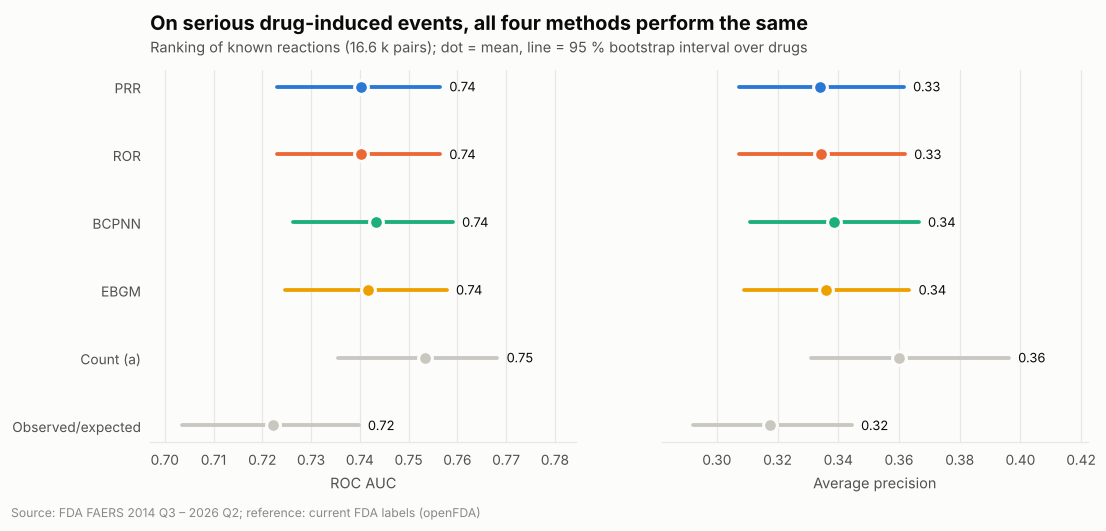

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
names = list(scores)
for ax, (metric, values) in zip(axes, {"ROC AUC": ci_auc, "Average precision": ci}.items()):
    dot_interval(ax, values, names)
    ax.set_xlabel(metric)
    span = values["high"].max() - values["low"].min()
    ax.set_xlim(values["low"].min() - 0.1 * span, values["high"].max() + 0.25 * span)
P.headline(axes[0], "On serious drug-induced events, all four methods perform the same",
           "Ranking of known reactions (16.6 k pairs); dot = mean, line = 95 % bootstrap interval over drugs")
P.source_note(fig, "Source: FDA FAERS 2014 Q3 – 2026 Q2; reference: current FDA labels (openFDA)")
save(fig, "ranking_metrics")

## 3. Each method's own signal threshold

In [6]:
thresholds = threshold_metrics(pairs)
thresholds.to_csv(TABLES / "threshold_metrics.csv")
thresholds.round(3)

,signals,sensitivity,specificity,ppv
method,,,,
PRR,167306,0.318,0.834,0.059
ROR,199480,0.446,0.805,0.069
BCPNN,166204,0.425,0.839,0.079
EBGM,99889,0.254,0.903,0.079


## 4. Machine learning: combining the scores with the case mix

Models are trained and tested with 5-fold cross-validation **grouped by drug**:
every prediction comes from a model that never saw that drug.

In [7]:
features = pair_features(con, pairs)
data = pairs.merge(features, on=["drug", "pt"])
X = design_matrix(data)
oof = out_of_fold_scores(X, data.label, data.drug)
for model in oof:
    data[model] = oof[model]

ml_scores = {**RANKING_SCORES, "Logistic regression": "Logistic regression",
             "Gradient boosting": "Gradient boosting"}
# Stricter check: test on reactions (preferred terms) the model has never seen.
oof_event = out_of_fold_scores(X, data.label, data.pt)
data["Gradient boosting (unseen events)"] = oof_event["Gradient boosting"]
ml_table = pd.concat({
    "All clinical events": compare_rankings(
        data, {**ml_scores, "Gradient boosting (unseen events)": "Gradient boosting (unseen events)"}),
    "Serious drug-induced events": compare_rankings(
        data[data.serious_event],
        {**ml_scores, "Gradient boosting (unseen events)": "Gradient boosting (unseen events)"}),
}, axis=1)
ml_table.to_csv(TABLES / "ml_metrics.csv")
ml_table.round(3)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

All clinical events                      \
                                                  auc     ap p@100 p@1000   
method                                                                      
PRR                                             0.635  0.045  0.07  0.069   
ROR                                             0.633  0.045  0.07  0.070   
BCPNN                                           0.727  0.076  0.14  0.166   
EBGM                                            0.714  0.065  0.08  0.092   
Logistic regression                             0.881  0.322  0.81  0.746   
Gradient boosting                               0.886  0.362  0.97  0.926   
Gradient boosting (unseen events)               0.896  0.356  0.90  0.780   

                                  Serious drug-induced events               \
                                                          auc     ap p@100   
method                                                                       
PRR                                                     0.741  0.335  0.68   
ROR                                                     0.741  0.335  0.68   
BCPNN                                                   0.744  0.339  0.68   
EBGM                                                    0.743  0.337  0.68   
Logistic regression                                     0.761  0.362  0.59   
Gradient boosting                                       0.778  0.390  0.57   
Gradient boosting (unseen events)                       0.778  0.388  0.62   

                                          
                                  p@1000  
method                                    
PRR                                0.434  
ROR                                0.435  
BCPNN                              0.441  
EBGM                               0.438  
Logistic regression                0.476  
Gradient boosting                  0.509  
Gradient boosting (unseen events)  0.495

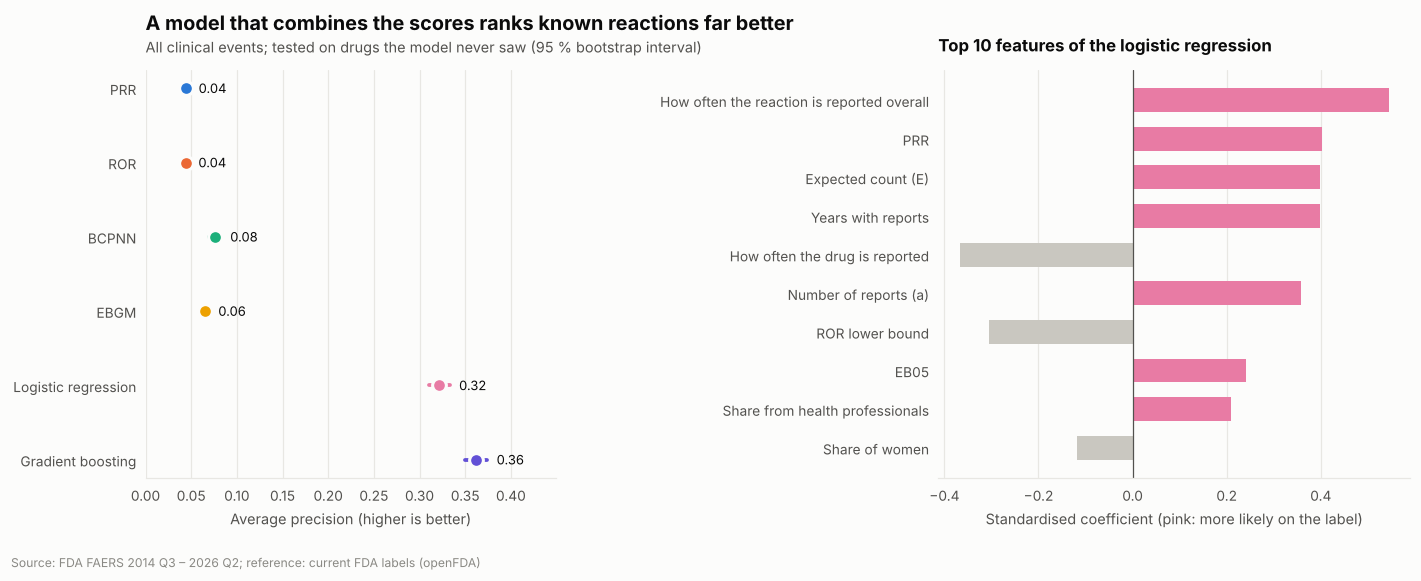

In [8]:
ml_ci = bootstrap_by_drug(data, ml_scores, metric="ap", n_boot=200)
coefs = logistic_coefficients(X, data.label)
FEATURE_NAMES = {
    "log_n_event": "How often the reaction is reported overall", "log_prr": "PRR",
    "log_expected": "Expected count (E)", "years_reported": "Years with reports",
    "log_n_drug": "How often the drug is reported", "log_a": "Number of reports (a)",
    "log_ror_lower": "ROR lower bound", "log_eb05": "EB05", "share_hcp": "Share from health professionals",
    "share_female": "Share of women", "ic025": "IC025", "share_serious": "Share of serious cases",
    "share_death": "Share of deaths", "share_hospital": "Share of hospitalisations",
    "share_consumer": "Share from consumers", "share_lawyer": "Share from lawyers",
    "share_us": "Share from the US", "median_age": "Median age", "share_recent": "Share of recent reports",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.15]})
dot_interval(axes[0], ml_ci, list(ml_scores))
axes[0].set_xlabel("Average precision (higher is better)")
axes[0].set_xlim(0, ml_ci["high"].max() * 1.2)
P.headline(axes[0], "A model that combines the scores ranks known reactions far better",
           "All clinical events; tested on drugs the model never saw (95 % bootstrap interval)")

ax = axes[1]
top = coefs.head(10)[::-1]
colors = [P.METHOD_COLORS["Logistic regression"] if v > 0 else P.NEUTRAL for v in top.values]
ax.barh([FEATURE_NAMES.get(f, f) for f in top.index], top.values, color=colors, height=0.62)
ax.axvline(0, color=P.MUTED, linewidth=0.8)
P.horizontal_bars(ax)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Standardised coefficient (pink: more likely on the label)")
ax.set_title("Top 10 features of the logistic regression", fontsize=11, pad=12)
P.source_note(fig, "Source: FDA FAERS 2014 Q3 – 2026 Q2; reference: current FDA labels (openFDA)")
fig.tight_layout()
save(fig, "ml_comparison")

## 5. Time to detection

In [9]:
first = pd.read_csv(TABLES / "first_signals.csv",
                    parse_dates=["label_date"] + [f"first_{m}" for m in METHODS])
positives = first[first.group == "label change"].copy()
negatives = first[first.group == "not on label"]
print(f"Dated positives: {len(positives):,} pairs, {positives.drug.nunique()} drugs, "
      f"label changes {positives.label_date.min().date()} to {positives.label_date.max().date()}")
print(f"Controls (not on label): {len(negatives):,}")

rows = []
for m in METHODS:
    lead = (positives.label_date - positives[f"first_{m}"]).dt.days / 30.44
    rows.append({
        "method": LABELS[m],
        "flagged at some point": positives[f"first_{m}"].notna().mean(),
        "flagged before the label change": (lead > 0).mean(),
        "median lead (months)": lead[lead > 0].median(),
        "controls flagged": negatives[f"first_{m}"].notna().mean(),
    })
timing = pd.DataFrame(rows).set_index("method")
timing.to_csv(TABLES / "time_to_detection.csv")
timing.round(3)

Dated positives: 4,785 pairs, 261 drugs, label changes 2016-09-22 to 2026-11-04
Controls (not on label): 20,000


,flagged at some point,flagged before the label change,median lead (months),controls flagged
method,,,,
PRR,0.534,0.476,42.510,0.218
ROR,0.632,0.553,42.477,0.245
BCPNN,0.600,0.519,41.689,0.199
EBGM,0.421,0.356,41.689,0.129


Caveat: the replay starts in 2014 Q3, and cases received before then are
already counted in the first quarter. A pair flagged at that first quarter
end was probably a signal long before, so its lead time is cut short
(left-censored). The table below keeps only **emerging** pairs, not flagged by
any method at the start of the window, and adds a head-to-head comparison:
for pairs flagged by both methods, which one flagged them first?

In [10]:
start = pd.Timestamp("2014-09-30")
already = (first[[f"first_{m}" for m in METHODS]] == start).any(axis=1)
emerging = first[~already]
pos_e, neg_e = emerging[emerging.group == "label change"], emerging[emerging.group == "not on label"]
rows = []
for m in METHODS:
    lead = (pos_e.label_date - pos_e[f"first_{m}"]).dt.days / 30.44
    rows.append({"method": LABELS[m],
                 "flagged before the label change": (lead > 0).mean(),
                 "median lead (months)": lead[lead > 0].median(),
                 "never flagged": pos_e[f"first_{m}"].isna().mean(),
                 "controls flagged": neg_e[f"first_{m}"].notna().mean()})
emerging_table = pd.DataFrame(rows).set_index("method")
emerging_table.to_csv(TABLES / "time_to_detection_emerging.csv")
print(f"Emerging positives: {len(pos_e):,}; controls: {len(neg_e):,}")
display(emerging_table.round(3))

pairs_h2h = []
for a, b in [("ebgm", "bcpnn"), ("ebgm", "prr"), ("bcpnn", "prr"), ("ror", "prr")]:
    both = pos_e[pos_e[f"first_{a}"].notna() & pos_e[f"first_{b}"].notna()]
    diff = (both[f"first_{b}"] - both[f"first_{a}"]).dt.days / 30.44
    pairs_h2h.append({"comparison": f"{LABELS[a]} vs {LABELS[b]}", "pairs": len(both),
                      "first method earlier": (diff > 0).mean(), "same quarter": (diff == 0).mean(),
                      "first method later": (diff < 0).mean(),
                      "median difference (months)": diff.median()})
head_to_head = pd.DataFrame(pairs_h2h).set_index("comparison")
head_to_head.to_csv(TABLES / "head_to_head.csv")
head_to_head.round(2)

Emerging positives: 3,759; controls: 19,470


,flagged before the label change,median lead (months),never flagged,controls flagged
method,,,,
PRR,0.349,38.633,0.579,0.197
ROR,0.431,38.403,0.468,0.224
BCPNN,0.393,37.516,0.505,0.179
EBGM,0.234,37.549,0.690,0.111


,pairs,first method earlier,same quarter,first method later,median difference (months)
comparison,,,,,
EBGM vs BCPNN,1161,0.04,0.35,0.61,-3.02
EBGM vs PRR,1161,0.04,0.32,0.65,-5.95
BCPNN vs PRR,1524,0.11,0.64,0.26,0.00
ROR vs PRR,1582,0.21,0.79,0.00,0.00


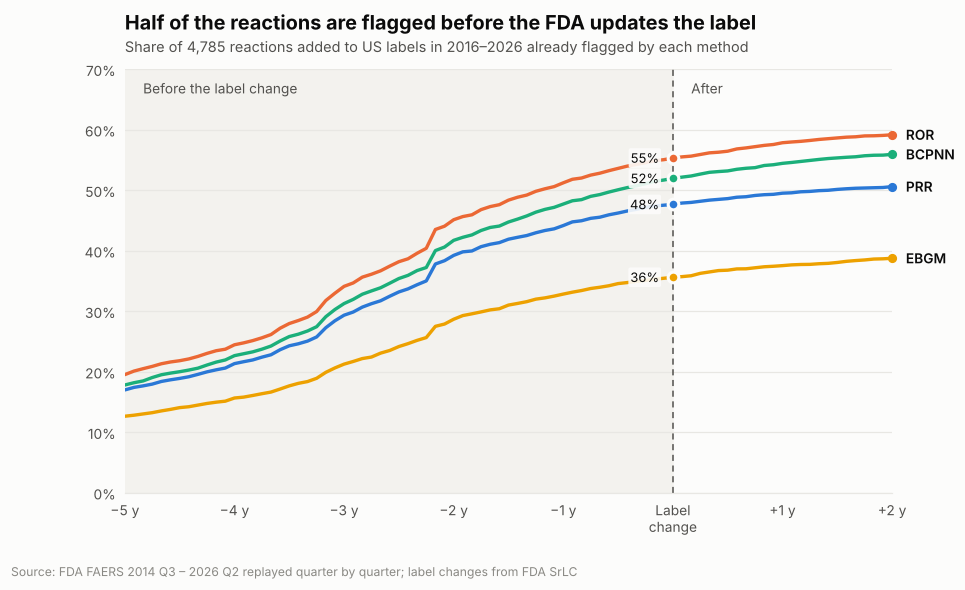

In [11]:
# Cumulative share of positives flagged, relative to the label change date.
months = np.arange(-60, 25)
fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(-60, 0, color="#f3f2ee", zorder=0)
series = {}
for m in METHODS:
    name = LABELS[m]
    lead = (positives.label_date - positives[f"first_{m}"]).dt.days / 30.44
    share = np.array([(lead >= -t).mean() * 100 for t in months])
    series[name] = share
    ax.plot(months, share, color=P.METHOD_COLORS[name])
    at_change = share[months == 0][0]
    ax.plot(0, at_change, "o", color=P.METHOD_COLORS[name], markersize=7,
            markeredgecolor=P.SURFACE, markeredgewidth=2, zorder=5)
    P.value_tag(ax, 0, at_change, f"{at_change:.0f}%")
ax.axvline(0, color=P.MUTED, linewidth=1, linestyle=(0, (4, 3)))
ax.text(-58, 66, "Before the label change", fontsize=9, color=P.MUTED)
ax.text(2, 66, "After", fontsize=9, color=P.MUTED)
ax.set_xlim(-60, 24)
ax.set_ylim(0, 70)
ax.set_xticks(range(-60, 25, 12),
              ["−5 y", "−4 y", "−3 y", "−2 y", "−1 y", "Label\nchange", "+1 y", "+2 y"])
P.percent(ax)
P.end_labels(ax, 24, series, P.METHOD_COLORS, min_gap=3)
P.headline(ax, "Half of the reactions are flagged before the FDA updates the label",
           f"Share of {len(positives):,} reactions added to US labels in 2016–2026 already flagged by each method")
P.source_note(fig, "Source: FDA FAERS 2014 Q3 – 2026 Q2 replayed quarter by quarter; label changes from FDA SrLC")
save(fig, "time_to_detection")

## 6. Key findings

**Ranking known reactions (current labels, 285 drugs, 982 k pairs)**
- On all clinical events, the four methods rank labelled reactions only modestly well (AUC 0.63–0.73), and **the raw number of reports beats all of them** (AUC 0.86). Labels list many common, non-specific reactions that are reported with every drug, which is exactly what disproportionality ignores by design. BCPNN (0.73) and EBGM (0.71) do clearly better than PRR and ROR (0.63): shrinkage helps when most pairs have very few reports.
- On **serious, typically drug-induced events** (16.6 k pairs) all methods converge (AUC ≈ 0.74, AP ≈ 0.34) and their bootstrap intervals overlap completely: **on this kind of event, the choice of method barely changes the ranking.**
- At their usual thresholds the methods trade sensitivity for specificity: ROR flags the most known reactions (45 %) and EBGM the fewest (25 %), but EBGM is the most specific (90 %). PPV is low for all (6–8 %), which is expected with a label-based reference that misses many true reactions.

**Machine learning**
- Gradient boosting on the four scores plus the case mix reaches AUC 0.89 / AP 0.36 on all events, against 0.08 for the best single method, and stays ahead on serious drug-induced events (AP about 0.39–0.41 depending on the run, vs 0.34). The gain holds when the model is tested on reactions it has never seen. (Gradient boosting trains in parallel, so its last decimals vary slightly between runs.)
- The strongest feature is how often the event is reported overall (`log_n_event`): part of the gain comes from learning *which kinds of events end up on labels*, not only which pairs are disproportionate. It is a useful triage score, not a replacement for the statistical signal.

**Time to detection (4,785 reactions added to labels 2016–2026)**
- Disproportionality often sees reactions **years before** the label change: by the date of the change, ROR had flagged 55 %, BCPNN 52 %, PRR 48 % and EBGM 36 %.
- Restricted to **emerging** signals (not flagged at the start of the window), the order is the same (ROR 43 %, BCPNN 39 %, PRR 35 %, EBGM 23 %), and the price is the same too: ROR also flags the most reactions that are *not* on the label (22 %), EBGM the fewest (11 %).
- **Head to head**, when both methods flag a reaction, EBGM is later than BCPNN in 61 % of cases (median 3 months) and later than PRR in 65 % (median 6 months). **EBGM buys fewer false alarms with later detection**; BCPNN offers the best balance of the four.

**Limitations**: the references come from text matching between MedDRA terms and label text (synonyms are missed, e.g. "suicidal thoughts" vs *suicidal ideation*); label changes are not the moment a reaction became *known*; the time replay uses the latest version of each case; and FAERS cannot establish causality.
